# Option analytics: letting the option surface choose the exposures

[`11a_pca`](11a_pca.ipynb) decomposed the panel of realized returns and used nothing else. It is
the control, and this notebook is the first thing measured against it.

**Instrumented PCA keeps the factor structure and conditions the exposures on the features.**
Where PCA gives each stock a loading estimated from its own return history, IPCA requires a
stock's exposure to be a linear function of *its own option-surface features on that date* -
implied volatility, the skew between puts and calls, the slope of the term structure, the gap
between implied and realized variance - and fits that map together with the factor returns. The
map is one set of coefficients shared by every stock and every date, so it is estimated on the
whole panel rather than on one cross-section at a time.

Two things follow from that, and they are the reason to read this notebook against
[`11a_pca`](11a_pca.ipynb) rather than on its own.

- **The features finally reach the factor structure.** In PCA they reached nothing. The distance
  between the two notebooks is what conditioning on the surface buys, measured rather than
  assumed, with the folds, the factor count and the scoring identical on both sides - though not
  the sample, for the reason the next point gives, which is why section 5 reads that distance as
  a bound rather than an estimate.
- **The panel no longer has to stay balanced.** PCA needs a stock to be the same stock with a
  usable return history across the training window. IPCA needs only that a stock have features on
  a date, because the exposure is computed from them rather than estimated from its past. On a
  universe that changes membership, that is the difference between dropping a name and pricing it.


<!-- ML4T_ZH_BEGIN c0000-p000 -->
# 選擇權分析：讓選擇權曲面決定暴露程度

[`11a_pca`](11a_pca.ipynb) 分解已實現報酬率面板，未使用其他資訊。它是對照基準，而本 Notebook 是第一個拿來與它比較的模型。

**工具變數主成分分析（IPCA）保留因子結構，並讓暴露程度取決於特徵。**PCA 根據每檔股票自身的報酬率歷史估計其負荷量；IPCA 則要求股票的暴露程度是*該股票當日選擇權曲面特徵*的線性函數，包括隱含波動率、買權與賣權之間的偏斜、期限結構的斜率，以及隱含與已實現變異數之間的差距，並同時擬合這項映射與因子報酬率。此映射是一組由所有股票和日期共用的係數，因此以整個面板估計，而非逐一在單一橫斷面上估計。

由此可得兩個結果，也說明了為何應對照 [`11a_pca`](11a_pca.ipynb) 解讀本 Notebook，而非單獨看它。

- **特徵終於進入因子結構。**在 PCA 中，特徵完全沒有作用。兩份 Notebook 之間的差距，是以實測而非假設方式衡量利用曲面設條件的效果；雙方的折疊、因子數和評分方式相同，但樣本不同，原因見下一點。因此，第 5 節會將這項差距解讀為界限，而非估計值。
- **面板不再需要保持平衡。**PCA 要求同一檔股票在整個訓練視窗都有可用的報酬率歷史。IPCA 只要求股票在某日有特徵，因為暴露程度是由這些特徵計算，而非從過去資料估計。若股票範圍的成員會變動，這就是捨棄一檔股票與為它定價的差別。
<!-- ML4T_ZH_END c0000-p000 -->

**A model with no epochs still has a checkpoint.** `config/ipca/ipca.yaml` declares
`checkpoint_interval: 0`, because IPCA is fitted by alternating least squares run to convergence
rather than trained for a number of epochs: a fold produces one fitted map and one set of
predictions. That is why the plan below shows a single checkpoint where
[`08_tabular_dl`](08_tabular_dl.ipynb) shows eight, and it is a property of the estimator rather
than a reduced setting.

**Learning objectives.** By the end of this notebook you will be able to:

- Say what conditioning an exposure on a characteristic changes, against estimating it from a
  return history.
- Explain why IPCA tolerates an unbalanced panel where PCA does not.
- Say what alternating least squares converging means here, and what the shared runner does when
  it does not.
- Read a population published for every declared label rather than for the traded one.

**Book reference**: Chapter 14, Section 14.5 (bridging economics and statistics with advanced
models). Chapter 6, Section 6.7 (Search accounting and run logging) introduces the run log this
notebook writes into.

**Prerequisites**: [`03_financial_features`](03_financial_features.ipynb) and
[`04_model_based_features`](04_model_based_features.ipynb) have written the feature matrices,
[`05_evaluation`](05_evaluation.ipynb) has established the walk-forward folds,
[`11_latent_factors`](11_latent_factors.ipynb) introduces the family, and
[`11a_pca`](11a_pca.ipynb) is the unconditioned baseline this one is read against.


<!-- ML4T_ZH_BEGIN c0000-p001 -->
**沒有訓練週期的模型仍有檢查點。**`config/ipca/ipca.yaml` 宣告 `checkpoint_interval: 0`，因為 IPCA 是透過交替最小平方法迭代至收斂來擬合，而非訓練固定數量的週期：每個折疊產生一項已擬合映射及一組預測。因此，下方計畫只顯示一個檢查點，而 [`08_tabular_dl`](08_tabular_dl.ipynb) 顯示八個；這是估計器的性質，並非縮減後的設定。

**學習目標。**完成本 Notebook 後，你將能夠：

- 說明讓暴露程度取決於特徵，與根據報酬率歷史估計暴露程度有何不同。
- 解釋為何 IPCA 可容納不平衡面板，而 PCA 不行。
- 說明交替最小平方法在此處收斂的意義，以及未收斂時共用執行器如何處理。
- 解讀為每個已宣告標籤發布的模型群體，而不只看交易所用的標籤。

**書籍參考**：第 14 章第 14.5 節（以進階模型連結經濟學與統計學）。第 6 章第 6.7 節（搜尋記帳與執行紀錄）介紹本 Notebook 寫入的執行紀錄。

**先備條件**：[`03_financial_features`](03_financial_features.ipynb) 和 [`04_model_based_features`](04_model_based_features.ipynb) 已寫出特徵矩陣，[`05_evaluation`](05_evaluation.ipynb) 已建立滾動向前驗證的折疊，[`11_latent_factors`](11_latent_factors.ipynb) 介紹此系列，而 [`11a_pca`](11a_pca.ipynb) 是解讀此模型所依據的不設條件基準。
<!-- ML4T_ZH_END c0000-p001 -->

**What it writes**: one training run per label and one complete validation prediction set per
label, in `run_log/registry.db` and under `run_log/training/` and `run_log/predictions/`, grouped
under a population named for this model. The family splits across five notebooks, so each
publishes its own population rather than one shared one.
[`13_model_analysis`](13_model_analysis.ipynb) compares them against the other families and
[`14_backtest`](14_backtest.ipynb) selects on validation backtest Sharpe. **Selection happens
there, not here.**

<!-- ML4T_ZH_BEGIN c0000-p002 -->
**產出內容**：每個標籤各有一筆訓練執行紀錄，以及一套完整的驗證集預測，寫入 `run_log/registry.db`，並存於 `run_log/training/` 與 `run_log/predictions/` 之下，依此模型命名的模型群體分組。此系列分散在五份 Notebook，因此各自發布模型群體，而非共用一個。[`13_model_analysis`](13_model_analysis.ipynb) 將它們與其他系列比較，[`14_backtest`](14_backtest.ipynb) 則依驗證回測的夏普比率選擇。**選擇發生在那裡，而非此處。**
<!-- ML4T_ZH_END c0000-p002 -->


In [1]:
"""Fit the declared option-analytics IPCA population on the walk-forward folds."""

import plotly.graph_objects as go
import polars as pl

from case_studies.research import (
    declared_labels,
    load_model_configs,
    model_requests,
    open_study,
    plan_models,
    planned_model_plan,
    primary_label,
    run_model_population,
)
from utils.style import COLORS, show_plotly_with_alt

In [2]:
LABELS: list[str] = []
EXECUTION_TIER = "canonical"
WORKSPACE: str = ""
PREVIEW_REDUCTIONS: dict = {}
POPULATION_NAME = ""
SUPERSEDES_POPULATION: str = ""

MODEL_NAME = "ipca"

In [3]:
study = open_study(
    "sp500_equity_option_analytics",
    execution_tier=EXECUTION_TIER,
    workspace=WORKSPACE or None,
    entry_point="11b_ipca",
)

## 1. Which labels, and what the configuration says

Every label whose training menu declares `latent_factors:` is fitted, and the cell below reads
which those are rather than this sentence asserting a count that would go stale the moment a
sixth label declared the family. What the names mean is the part prose has to supply:
`fwd_ret_5d` is the stock's total return over the five trading days after the decision date,
`fwd_ret_10d` the same over ten, and `fwd_ret_risk_adj_5d` the five-day return divided by a
measure of its own dispersion. A `fwd_dir_*` classification label declaring only linear and
gradient boosting is absent here rather than dropped.

<!-- ML4T_ZH_BEGIN c0004-p000 -->
## 1. 有哪些標籤，以及設定說明了什麼

所有訓練選單宣告 `latent_factors:` 的標籤都會進行擬合。下方儲存格會讀取有哪些標籤，而非在本文寫死一個可能在第六個標籤宣告此系列時失效的數量。文字需要補充的是這些名稱的意義：`fwd_ret_5d` 是決策日後五個交易日內的股票總報酬率，`fwd_ret_10d` 是十個交易日的對應報酬率，而 `fwd_ret_risk_adj_5d` 是五日報酬率除以衡量其自身離散程度的數值。若 `fwd_dir_*` 分類標籤只宣告線性模型與梯度提升，它就不會出現在此，而不是遭到遺漏。
<!-- ML4T_ZH_END c0004-p000 -->


In [4]:
declared_labels(study, "latent_factors")

('fwd_ret_10d', 'fwd_ret_5d', 'fwd_ret_risk_adj_5d')

`case_studies/config/ipca/ipca.yaml` declares `n_factors`, how many common factors to extract,
and `checkpoint_interval: 0` for the reason given above. `config/setup.yaml` adds three more
under `modeling.latent_factors.model_kwargs.ipca`: `max_iter`, the alternating least squares
iteration budget, and `factor_ridge` and `gamma_ridge`, the penalties on its two least-squares
steps.

The order those are read in matters, because the same value can be declared twice.
`config/setup.yaml` wins where it declares a key, the preset supplies the rest, and a built-in
default is reached only when neither does. Here setup declares the iteration and ridge settings
and the preset declares `n_factors`, so nothing is contested. A reduced run may override either
through `PREVIEW_REDUCTIONS`, where the reduction becomes part of the preview identity rather
than a silent change - which matters for this model in particular, and section 3 says why.

<!-- ML4T_ZH_BEGIN c0006-p000 -->
`case_studies/config/ipca/ipca.yaml` 宣告 `n_factors`，即擷取的共同因子數，以及因前述原因設定的 `checkpoint_interval: 0`。`config/setup.yaml` 在 `modeling.latent_factors.model_kwargs.ipca` 下另外加入三項設定：`max_iter` 是交替最小平方法的迭代次數上限，`factor_ridge` 與 `gamma_ridge` 則是兩個最小平方法步驟的懲罰項。

讀取順序很重要，因為同一個值可能被宣告兩次。只要 `config/setup.yaml` 宣告某個鍵值，它就優先；其餘由預設設定提供，只有兩者都沒有宣告時才使用內建預設值。此處 setup 宣告迭代與 ridge 設定，預設設定則宣告 `n_factors`，因此沒有衝突。縮減版執行可再透過 `PREVIEW_REDUCTIONS` 覆寫任一設定，縮減內容會成為預覽識別資訊的一部分，而非默默改變；這對此模型尤其重要，第 3 節會說明原因。
<!-- ML4T_ZH_END c0006-p000 -->


In [5]:
configs = load_model_configs(
    study,
    "latent_factors",
    labels=LABELS or None,
    config_names=[MODEL_NAME],
)
configs

family,label,config_name,model_class,params
str,str,str,str,str
"""latent_factors""","""fwd_ret_10d""","""ipca""","""""","""n_factors=5"""
"""latent_factors""","""fwd_ret_5d""","""ipca""","""""","""n_factors=5"""
"""latent_factors""","""fwd_ret_risk_adj_5d""","""ipca""","""""","""n_factors=5"""


`LABELS` narrows what is fitted, and a narrowed run declares a different set of members than the
canonical population does. A population is immutable once written, so such a run must publish
under its own name: on a fresh workspace it would otherwise register an incomplete snapshot under
the canonical one, and where the full population already exists the registry refuses it.

The comparison is against this model's own declared rows rather than the whole `latent_factors`
catalog. The family is split across five notebooks and each publishes one model, so the complete
catalog is five times what this one publishes, and comparing against it would report every
canonical run as narrowed.

<!-- ML4T_ZH_BEGIN c0008-p000 -->
`LABELS` 會縮小擬合範圍，而縮小範圍的執行所宣告的成員集合，與標準模型群體不同。模型群體一旦寫入就不可變，因此這類執行必須以自己的名稱發布：在全新工作區中，否則會以標準名稱登錄不完整的快照；若完整群體已存在，登錄機制則會拒絕。

比較時應以此模型自己宣告的資料列為準，而非整個 `latent_factors` 目錄。此系列分散在五份 Notebook，且每份只發布一個模型，所以完整目錄的規模是此模型發布內容的五倍；若與整個目錄比較，每次標準執行都會被誤判為縮小範圍。
<!-- ML4T_ZH_END c0008-p000 -->


In [6]:
declared = load_model_configs(study, "latent_factors", config_names=[MODEL_NAME])
if set(configs.get_column("label")) != set(declared.get_column("label")) and not POPULATION_NAME:
    raise ValueError(
        f"this run fits {configs.height} of the {declared.height} declared labels, so it cannot "
        "publish the canonical population; pass POPULATION_NAME to give it its own"
    )

### Where this one runs, and why it is not the family's device

`config/setup.yaml` declares the latent-factor family on CUDA, which is right for the three
neural members. IPCA is not one of them: `run_ipca_fold` is alternating least squares over the
panel, numpy and scipy, and takes no device at all. The device nonetheless sits inside the hashed computation rather than
beside it as provenance, so leaving the family's value in place would record a computation that
did not happen and would make this population's identity depend on whether the machine had a GPU.
It is declared here instead, and a run on another device has to publish under its own name.

<!-- ML4T_ZH_BEGIN c0010-p000 -->
### 此模型在哪裡執行，以及為何不使用系列的裝置設定

`config/setup.yaml` 將潛在因子系列的裝置宣告為 CUDA，這適合其中三個神經網路成員。IPCA 不屬於它們：`run_ipca_fold` 是以 numpy 和 scipy 對面板執行交替最小平方法，完全不需要裝置。然而，裝置設定被納入雜湊計算，而不只是旁列的來源紀錄；若沿用系列設定，便會記錄一項並未發生的運算，也會使此模型群體的識別資訊取決於機器是否有 GPU。因此，這裡另行宣告裝置；在其他裝置執行時，必須以自己的名稱發布。
<!-- ML4T_ZH_END c0010-p000 -->


In [7]:
PUBLISHED_DEVICE = "cpu"
overrides = {"device": PUBLISHED_DEVICE}
print(f"training device: {PUBLISHED_DEVICE}")

training device: cpu


## 2. Binding the declarations to the data

A menu entry names an estimator and a factor count. It does not say which feature columns exist
today, where the walk-forward folds fall, or which symbol-date pairs have both a return and a
label. **Planning** works all of that out - and every training and prediction identity with it -
without fitting anything. Four things to check:

- **`feature_count` and `eligible_rows` agree across the rows.** A row that differs is a label
  measured on a different sample from its neighbours. They differ *between* labels, because a
  ten-day forward window runs out earlier than a five-day one.
- **`folds` is the same everywhere**, and equals the number of walk-forward splits
  [`05_evaluation`](05_evaluation.ipynb) established.
- **`validation_start` and `validation_end` bracket the development sample**, with none of the
  held-out 2021 tail visible.
- **`checkpoints` is 1**, for the reason the configuration gives above.

`feature_count` means something here that it did not in [`11a_pca`](11a_pca.ipynb). There it was
a property of the request that the fit ignored, because a decomposition of the return panel uses
no feature columns. Here every one of those columns is an instrument: the map from features to
exposures carries a coefficient per column per factor, so `feature_count` times `n_factors` is
the size of what is being estimated, and it is the number to read against `eligible_rows` when
asking whether the panel can identify it.

<!-- ML4T_ZH_BEGIN c0012-p000 -->
## 2. 將宣告與資料對應

選單項目指定估計器與因子數，卻不會說明目前有哪些特徵欄位、滾動向前驗證的折疊落在哪裡，或哪些股票代號與日期的組合同時具有報酬率和標籤。**規劃**會釐清這一切，並確定每筆訓練和預測的識別資訊，過程中不會擬合任何模型。請檢查四件事：

- **各資料列的 `feature_count` 與 `eligible_rows` 應一致。**若某列不同，其標籤就是在與相鄰列不同的樣本上衡量。這些數值在*不同*標籤之間會不同，因為十日遠期視窗會比五日視窗更早沒有資料。
- **`folds` 在各處相同**，並等於 [`05_evaluation`](05_evaluation.ipynb) 建立的滾動向前驗證切分數。
- **`validation_start` 與 `validation_end` 界定開發樣本的起訖**，不包含保留的 2021 年尾段資料。
- **`checkpoints` 為 1**，原因見上方設定說明。

此處的 `feature_count` 與 [`11a_pca`](11a_pca.ipynb) 中的意義不同。在 PCA 中，它只是請求的一項屬性，擬合時會忽略，因為分解報酬率面板不需要特徵欄位。在這裡，每個欄位都是工具變數：從特徵到暴露程度的映射，對每個欄位、每個因子都有一個係數。因此，`feature_count` 乘以 `n_factors` 就是待估計量的大小；要判斷面板能否識別它，應將此數值與 `eligible_rows` 比較。
<!-- ML4T_ZH_END c0012-p000 -->


In [8]:
requests = model_requests(
    study,
    configs,
    execution_tier=EXECUTION_TIER,
    overrides=overrides,
    preview_reductions=PREVIEW_REDUCTIONS,
)
plan = plan_models(study, requests=requests)

planned_model_plan(plan).select(
    "label",
    "config_name",
    "task",
    "feature_count",
    "eligible_rows",
    "folds",
    "checkpoints",
    "validation_start",
    "validation_end",
)

label,config_name,task,feature_count,eligible_rows,folds,checkpoints,validation_start,validation_end
str,str,str,i64,i64,i64,i64,str,str
"""fwd_ret_10d""","""ipca""","""regression""",48,192139,2,1,"""2019-01-07 00:00:00""","""2020-12-16 00:00:00"""
"""fwd_ret_5d""","""ipca""","""regression""",48,194813,2,1,"""2019-01-07 00:00:00""","""2020-12-23 00:00:00"""
"""fwd_ret_risk_adj_5d""","""ipca""","""regression""",48,194748,2,1,"""2019-01-07 00:00:00""","""2020-12-23 00:00:00"""


The plan is also where a short population is visible. A run that fitted fewer labels than the
menu declares would still print an IC table and still register its rows; what it would not do is
announce the gap.

<!-- ML4T_ZH_BEGIN c0014-p000 -->
計畫也能揭示模型群體是否缺少成員。若某次執行擬合的標籤少於選單宣告的數量，它仍會印出 IC 表並登錄其資料列，卻不會主動指出缺口。
<!-- ML4T_ZH_END c0014-p000 -->


In [9]:
planned_pairs = {(member.label, member.config_name) for member in plan.members}
requested_pairs = set(zip(configs["label"], configs["config_name"], strict=True))
if planned_pairs != requested_pairs:
    raise RuntimeError(
        "the plan does not match the loaded IPCA menu; "
        f"missing {sorted(requested_pairs - planned_pairs)}, "
        f"unexpected {sorted(planned_pairs - requested_pairs)}"
    )
print(f"{len(requested_pairs)} label-configuration pairs")
print(f"{len(plan.expected_training_hashes)} training identities")
print(f"{len(plan.expected_prediction_hashes)} validation prediction sets")

3 label-configuration pairs
3 training identities
3 validation prediction sets


## 3. Fitting the population

`run_model_population` runs every planned request. For one request it walks the folds, and on
each one:

1. takes the stock-dates inside that fold's training window, with their features and returns,
2. alternates between two least-squares problems until they stop moving: given the current map
   from features to exposures, solve for the factor returns on each date; given those factor
   returns, solve for the map. Both steps are ridge-penalised at the strengths
   `config/setup.yaml` declares,
3. applies the fitted map to the validation dates' features to get each stock's exposure there,
   and multiplies by the training window's factor returns to get a predicted return.

Step 3 is what makes this a forecast rather than a decomposition: the map and the factor returns
come from the training window only, and the validation dates contribute nothing to either.

**Alternating least squares can fail to converge, and the shared runner refuses the result when
it does.** `case_studies/utils/latent_factors/cv.py` collects each fold's convergence flag and
raises before anything is registered, rather than publishing predictions from an incomplete fit.
That is worth knowing as a reader because the failure is a property of the data rather than of
the code: the map has `feature_count` times `n_factors` coefficients to identify, and a
cross-section with fewer names than that on a date cannot identify them at any iteration budget.
It is why the CI fixture for this notebook declares a reduced `n_factors` - twenty-odd symbols
per date do not identify five factors - and why that reduction is declared in
`PREVIEW_REDUCTIONS`, where it changes the preview identity instead of quietly relaxing a guard.


<!-- ML4T_ZH_BEGIN c0016-p000 -->
## 3. 擬合模型群體

`run_model_population` 會執行每項已規劃的請求。對每項請求，它逐一處理各折疊，並在每個折疊中：

1. 取得該折疊訓練視窗內各股票與日期的特徵及報酬率；
2. 在兩個最小平方法問題之間交替求解，直到結果不再變動：給定目前從特徵到暴露程度的映射，求出各日的因子報酬率；再給定這些因子報酬率，求出映射。兩步驟都採用 `config/setup.yaml` 宣告的強度施加 ridge 懲罰；
3. 將擬合後的映射套用至驗證日期的特徵，得到各股票當日的暴露程度，再乘以訓練視窗的因子報酬率，取得預測報酬率。

第 3 步使結果成為預測，而非單純分解：映射與因子報酬率都只來自訓練視窗，驗證日期不參與兩者的估計。

**交替最小平方法可能無法收斂；若未收斂，共用執行器會拒絕結果。**`case_studies/utils/latent_factors/cv.py` 收集每個折疊的收斂旗標，在登錄任何內容之前就拋出錯誤，而不會發布未完成擬合的預測。讀者需要知道，這類失敗是資料的性質，不是程式碼的問題：映射有 `feature_count` 乘以 `n_factors` 個係數待識別；若某日橫斷面的股票數比這個數量還少，不論給多少迭代次數都無法識別。因此，本 Notebook 的 CI 測試資料宣告縮減的 `n_factors`：每日約二十檔股票無法識別五個因子。此縮減在 `PREVIEW_REDUCTIONS` 中宣告，會改變預覽識別資訊，而非悄悄放寬檢查。
<!-- ML4T_ZH_END c0016-p000 -->

**This notebook passes the plan rather than resolved requests, and on this family that changes
what the plan table can show rather than how the fitting is ordered.** The linear, boosted and
TabM adapters each provide a batch runner that prepares one fold set for several configurations;
the latent-factor adapter provides none, so every request is fitted on its own whichever path is
taken. There would be nothing to share in any case: this notebook publishes one model against
three labels, and each label is a different set of rows. What passing the plan costs is
`eligible_entities`, which needs the eligibility keys themselves; `eligible_rows` above moves
whenever the universe does, so the check that column existed for is still made.

**What the call publishes is a population**: a named, immutable list of the prediction sets it
will produce, written down before the first fit. Afterwards every member must exist and be
complete, which is what makes the downstream comparison well defined.

<!-- ML4T_ZH_BEGIN c0016-p001 -->
**本 Notebook 傳入的是計畫，而非已解析的請求；對此系列而言，這改變的是計畫表能顯示的內容，而非擬合順序。**線性、提升樹和 TabM 配接器都有批次執行器，可為多種設定準備同一組折疊；潛在因子配接器沒有，因此無論走哪條路，每項請求都會獨立擬合。況且此處也沒有可共用的內容：本 Notebook 為三個標籤發布一個模型，而每個標籤對應不同的資料列集合。傳入計畫所犧牲的是 `eligible_entities`，因為它需要適用資格鍵值本身；上方的 `eligible_rows` 會隨股票範圍變動，所以該欄位原本要做的檢查仍然會執行。

**此呼叫發布的是一個模型群體**：在首次擬合前，先記下它將產生的具名、不可變預測集清單。之後每個成員都必須存在且完整，下游比較才有明確依據。
<!-- ML4T_ZH_END c0016-p001 -->


In [10]:
def catalog_labels(execution) -> int:
    """Number of distinct labels the execution published, read from its catalog rows."""
    return execution.catalog_rows.get_column("label").n_unique()


population_name = POPULATION_NAME or f"sp500_equity_option_analytics-{MODEL_NAME}-validation-v1"
execution, population = run_model_population(
    study, plan, population_name=population_name, supersedes=SUPERSEDES_POPULATION or None
)

# No per-fold counts: this family's runner reports none, and two zeros would read as a failed fit.
print(f"{len(execution.runs)} training runs across {catalog_labels(execution)} labels")
print(f"population {population.name}: {len(population.members)} prediction sets")

Latent factor CV: 1 models × 2 folds
Log file: case_studies/sp500_equity_option_analytics/run_log/training/8d990b815973/.models.14a1c40bce6249ac9bdf2b3be55299b3.tmp/latent_factors.log
Scoring: dates=all cadence=- step=1 checkpoint_selection=fixed reporting_epoch=0
  ipca (K=5):


    Fold 0: ragged train=475, val=251, max_N=503


      fold 0: reported_epoch=0, IC=+0.0099, 4.0s


    Fold 1: ragged train=493, val=241, max_N=503


      fold 1: reported_epoch=0, IC=-0.0261, 4.2s
    -> reporting epoch=0 (fixed), IC=-0.0077 (13.4s)


  Best: ipca (IC=-0.0077)


... (9 outputs left out)

    Fold 1: ragged train=498, val=246, max_N=503


      fold 1: reported_epoch=0, IC=+0.0177, 1.9s
    -> reporting epoch=0 (fixed), IC=+0.0426 (11.6s)


  Best: ipca (IC=+0.0426)


3 training runs across 3 labels
population sp500_equity_option_analytics-ipca-validation-v1: 3 prediction sets


`reused` is not zero on a second run. Every identity is re-derived from the inputs, the registry
already holds the matching rows, and the runner returns the stored result rather than fitting
again - so re-running this notebook unchanged costs the time it takes to read the data.

### Running configurations of your own

The published run log is read-only. To add runs, open the study against a workspace, which holds
its own registry and artifacts and reads the same labels and features:

```python
study = open_study("sp500_equity_option_analytics", workspace="~/ml4t-experiments")
configs = load_model_configs(
    study, "latent_factors", labels=["fwd_ret_5d"], config_names=["pca"]
)
requests = model_requests(study, configs, overrides={"device": "cpu"})
plan = plan_models(study, requests=requests)
execution, population = run_model_population(study, plan, population_name="my-pca-v1")
```

To change the number of factors for your own run, edit `case_studies/config/pca/pca.yaml`, or
declare `n_factors` under `modeling.latent_factors.model_kwargs.pca` in `config/setup.yaml` to
override the preset for this case study alone. Note which of those you want: the preset is shared
by every case study that declares `pca`, so editing it moves the training identity of all of
them. Either way the result registers as a new row beside the old one rather than replacing it.
[`RUN_LOG.md`](../RUN_LOG.md#running-your-own-configurations) covers the rest.

<!-- ML4T_ZH_BEGIN c0018-p000 -->
第二次執行時，`reused` 不會是零。系統會從輸入重新推導每個識別資訊，登錄機制中已有相符資料列，執行器便會回傳儲存的結果，而不再擬合。因此，在內容未變的情況下重跑此 Notebook，只需花費讀取資料的時間。

### 執行自己的設定

已發布的執行紀錄是唯讀的。若要新增執行，請在工作區中開啟研究；它有自己的登錄機制和產出檔案，但讀取相同的標籤與特徵：

```python
study = open_study("sp500_equity_option_analytics", workspace="~/ml4t-experiments")
configs = load_model_configs(
    study, "latent_factors", labels=["fwd_ret_5d"], config_names=["pca"]
)
requests = model_requests(study, configs, overrides={"device": "cpu"})
plan = plan_models(study, requests=requests)
execution, population = run_model_population(study, plan, population_name="my-pca-v1")
```

若要改變自己執行的因子數，可編輯 `case_studies/config/pca/pca.yaml`，或宣告 `n_factors`，將其置於 `modeling.latent_factors.model_kwargs.pca` 下的 `config/setup.yaml`，只針對此案例研究覆寫預設設定。請留意選擇哪一種方式：所有宣告 `pca` 的案例研究都共用該預設設定，因此編輯它會改變所有這些案例研究的訓練識別資訊。無論哪種方式，新結果都會登錄為舊資料列旁的新列，而不會取代舊列。其餘說明見 [`RUN_LOG.md`](../RUN_LOG.md#running-your-own-configurations)。
<!-- ML4T_ZH_END c0018-p000 -->


## 4. What came out

One row per label. The **information coefficient** is the rank correlation, on one validation
date, between the stocks ordered by the model's prediction and the stocks ordered by the return
they went on to earn.

`ic_mean` aggregates that **over folds, not over days**: each fold's own mean IC is computed and
those are averaged with equal weight (`latent_factors/cv.py`, and
`registry/metrics.py` states the convention). With folds of unequal length the fold mean and the
pooled daily mean are different numbers, and this column is the first.

`ic_n_days` is how many validation dates produced a defined correlation, and it decides which rows
are comparable with each other. `auc_scored_against` says what the AUC column was scored against:
a regression row has no classes of its own and is scored as a ranking signal against a declared
direction sibling, so `fwd_ret_5d` is scored against `fwd_dir_5d` and `fwd_ret_10d` against
`fwd_dir_10d`. `fwd_ret_risk_adj_5d` declares no sibling and carries no AUC; null there means not
computed, not zero.

The published catalog is checked against the population planned before fitting rather than against
its own row count, because a run that lost a member would otherwise report a shorter table and
nothing else.

<!-- ML4T_ZH_BEGIN c0019-p000 -->
## 4. 產出結果

每個標籤各有一列。**資訊係數**是在單一驗證日期，以模型預測值對股票排序，與以股票後續實現報酬率排序，兩者之間的等級相關係數。

`ic_mean` 是**跨折疊而非跨日期**彙總：先計算每個折疊自己的平均 IC，再將這些平均值等權平均（`latent_factors/cv.py`，而 `registry/metrics.py` 說明採用的慣例）。折疊長度不同時，折疊平均值與合併後的逐日平均值並不相同；此欄位採用前者。

`ic_n_days` 是能算出相關係數的驗證日期數，並決定哪些資料列可以互相比較。`auc_scored_against` 表示 AUC 欄位是針對什麼評分：迴歸資料列本身沒有類別，因此會將其視為排序訊號，對已宣告的方向分類同層標籤評分；所以 `fwd_ret_5d` 對 `fwd_dir_5d` 評分，而 `fwd_ret_10d` 對 `fwd_dir_10d` 評分。`fwd_ret_risk_adj_5d` 沒有宣告同層標籤，也就沒有 AUC；該處的空值表示未計算，不代表零。

已發布的目錄會與擬合前規劃的模型群體比較，而非只核對自身資料列數；否則若某次執行遺失成員，只會呈現一張較短的表，沒有其他提示。
<!-- ML4T_ZH_END c0019-p000 -->


In [11]:
catalog = execution.catalog_rows.select(
    "config_name",
    "label",
    "task",
    "complete",
    "checkpoint_kind",
    "checkpoint_value",
    "ic_mean",
    "ic_std",
    "ic_t",
    "ic_n_days",
    "auc_mean_daily",
    pl.col("direction_label").alias("auc_scored_against"),
    "n_folds",
    "training_hash",
    "prediction_hash",
).sort("label")

if set(catalog.get_column("prediction_hash")) != set(plan.expected_prediction_hashes):
    raise RuntimeError("the published catalog differs from the population planned before fitting")
if catalog.filter(~pl.col("complete")).height:
    raise RuntimeError("a partial IPCA prediction set cannot pass to backtesting")
if catalog.select("label", "config_name", "checkpoint_value").n_unique() != catalog.height:
    raise RuntimeError("each label and checkpoint must identify one prediction set")

primary = primary_label(study)
present = sorted(set(catalog.get_column("label")))
# The primary label leads when it was fitted. A subset run that leaves it out orders by whichever
# label it did fit rather than by one that is not there.
ordered_labels = [label for label in [primary] if label in present] + [
    label for label in present if label != primary
]
print(f"{catalog.height} candidate models across {len(ordered_labels)} labels")
catalog.select(
    "label",
    "task",
    "checkpoint_value",
    "ic_mean",
    "ic_std",
    "ic_t",
    "ic_n_days",
    "auc_mean_daily",
    "auc_scored_against",
)

3 candidate models across 3 labels


label,task,checkpoint_value,ic_mean,ic_std,ic_t,ic_n_days,auc_mean_daily,auc_scored_against
str,str,i64,f64,f64,f64,f64,f64,str
"""fwd_ret_10d""","""regression""",0,-0.008086,0.017965,-0.636573,492.0,0.509792,"""fwd_dir_10d"""
"""fwd_ret_5d""","""regression""",0,0.007236,0.001483,6.902722,497.0,0.51376,"""fwd_dir_5d"""
"""fwd_ret_risk_adj_5d""","""regression""",0,0.042409,0.024669,2.431158,497.0,null,null


### One map, three targets

The features, the folds, the factor count and the ridge strengths are identical across these
rows. What changes is which forward return the exposures were fitted against - and unlike
[`11a_pca`](11a_pca.ipynb), where the decomposition never saw the target at all, here the target
enters the fit. So a gap between these rows says the map itself came out different, not just that
the same forecast was scored three ways.

`ic_t` is the t-statistic across those fold means, not a Newey-West statistic on the daily
series - the registry keeps the HAC-corrected version separately as `ic_t_hac`, and that is the
inferential one. Either way it is a diagnostic and not a selection rule: the series is short,
overlapping multi-day returns make successive days dependent, and the folds have been read many
times over by the time a case study reaches this notebook.

<!-- ML4T_ZH_BEGIN c0021-p000 -->
### 一項映射、三個目標

這些資料列的特徵、折疊、因子數和 ridge 強度都相同。改變的是擬合暴露程度所依據的遠期報酬率；不同於 [`11a_pca`](11a_pca.ipynb) 的分解完全不接觸目標值，這裡的目標值會進入擬合。因此，資料列間的差距表示映射本身不同，而不只是同一組預測以三種方式評分。

`ic_t` 是這些折疊平均值的 t 統計量，不是逐日序列的 Newey-West 統計量。登錄機制另以 `ic_t_hac` 保存經 HAC 修正的版本，那才是用於推論的數值。無論哪種統計量都只是診斷指標，不是選擇規則：序列很短，重疊的多日報酬率使相鄰日期相依，而且在案例研究進展到本 Notebook 時，這些折疊早已被反覆查看多次。
<!-- ML4T_ZH_END c0021-p000 -->


In [12]:
by_label = catalog.select(
    "label",
    "task",
    ic_mean=pl.col("ic_mean"),
    ic_t=pl.col("ic_t"),
    scored_dates=pl.col("ic_n_days"),
    # `ic_n_days` counts the days behind `ic_mean_daily`, the pooled daily statistic - not the
    # folds behind `ic_mean`, which is what the rows are ordered by. So this column is a
    # comparability guarantee about one statistic attached to a ranking on another. It is kept
    # because unequal day counts are still the thing that makes two rows incomparable, and
    # flagged because the two are not the same measurement: the registry averages folds for
    # `ic_mean` and computes the daily family separately, so `ic_n_days` describes one and the
    # ordering uses the other. Reading the ordering on `ic_mean_daily` would need
    # `PredictionCatalog` to carry it.
    full_coverage=pl.col("ic_n_days") == pl.col("ic_n_days").max(),
).sort("ic_mean", descending=True)
by_label

label,task,ic_mean,ic_t,scored_dates,full_coverage
str,str,f64,f64,f64,bool
"""fwd_ret_risk_adj_5d""","""regression""",0.042409,2.431158,497.0,true
"""fwd_ret_5d""","""regression""",0.007236,6.902722,497.0,true
"""fwd_ret_10d""","""regression""",-0.008086,-0.636573,492.0,false


### The same map against each target

One bar per label, on one axis, with the primary target first. The bars are the quantity the
downstream comparison uses; the axis is shared so the distance between them is readable rather
than each panel filling itself.

<!-- ML4T_ZH_BEGIN c0023-p000 -->
### 以同一項映射面對各個目標

每個標籤各有一根長條，共用一條座標軸，主要目標排在最前面。長條表示下游比較使用的量；共用座標軸可看出彼此差距，而不會讓每個圖面各自填滿。
<!-- ML4T_ZH_END c0023-p000 -->


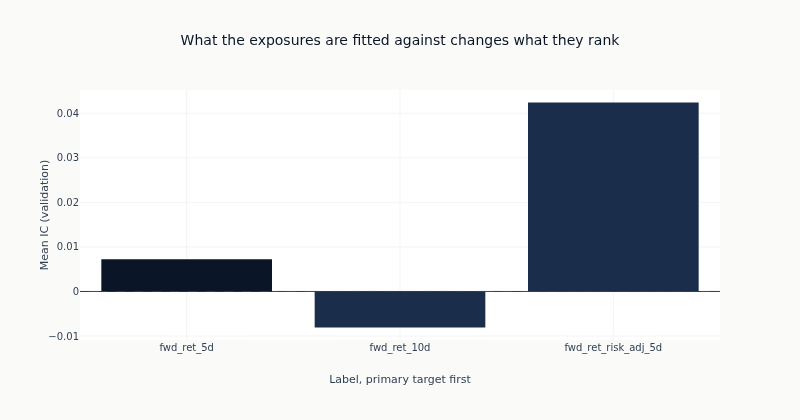

In [13]:
panel = catalog.with_columns(
    rank=pl.col("label").replace_strict(
        {label: index for index, label in enumerate(ordered_labels)}, return_dtype=pl.Int32
    )
).sort("rank")
fig = go.Figure(
    go.Bar(
        x=panel.get_column("label").to_list(),
        y=panel.get_column("ic_mean").to_list(),
        marker_color=[
            COLORS["blue"] if label == primary else COLORS["slate"]
            for label in panel.get_column("label")
        ],
        showlegend=False,
    )
)
fig.add_hline(y=0, line_width=1, line_dash="dash", line_color=COLORS["neutral"])
fig.update_yaxes(title_text="Mean IC (validation)")
fig.update_xaxes(title_text="Label, primary target first")
fig.update_layout(
    title="What the exposures are fitted against changes what they rank",
    height=420,
    width=800,
    margin=dict(t=90),
)
# Which side of zero each bar sits on is a fact about the frame, so the alt text reads it rather
# than asserting a shape the next run may not reproduce.
sides = "; ".join(
    f"{row['label']} {'above' if row['ic_mean'] > 0 else 'below'} zero"
    for row in panel.select("label", "ic_mean").iter_rows(named=True)
)
show_plotly_with_alt(
    fig,
    "Bar chart of mean validation information coefficient, one bar per label on one axis, with the "
    "primary target in dark navy first and the two variants in slate, and a dashed zero line. "
    f"Counted from the frame: {sides}.",
)

## 5. What to notice

**The estimator is the same and only the target moves.** These rows share the features, the
folds, the dates scored, the factor count and the ridge strengths. `fwd_ret_10d` is the same
construction over twice the horizon, and `fwd_ret_risk_adj_5d` is `fwd_ret_5d` divided by a
measure of its own dispersion - so a gap between those two rows is a statement about scaling by
width and nothing else.

**This notebook and [`11a_pca`](11a_pca.ipynb) differ in two things, not one, and the second one
limits what the comparison can say.** Same folds, same factor count, same scoring, same three
labels. PCA estimates each stock's loading from its own return history and never sees an
option-surface column; IPCA requires the loading to be a linear function of exactly those
columns. That is the difference the comparison is for.

The second difference is the sample. The section above is explicit that IPCA does not need a
balanced panel and PCA does, and the consequence is that the two populations are not scored on
the same rows: IPCA covers about a tenth more of the panel on every label - 192,139 against
175,360 on `fwd_ret_10d`, 194,813 against 177,682 on `fwd_ret_5d`, 194,748 against 177,769 on
`fwd_ret_risk_adj_5d`. The extra rows are the names PCA had to drop for want of a complete return
history, which are systematically the shorter-lived and less liquid ones.


<!-- ML4T_ZH_BEGIN c0025-p000 -->
## 5. 值得留意的地方

**估計器相同，只有目標變動。**這些資料列共用特徵、折疊、評分日期、因子數和 ridge 強度。`fwd_ret_10d` 是期間加倍但建構方式相同的標籤，而 `fwd_ret_risk_adj_5d` 是 `fwd_ret_5d` 除以衡量其自身離散程度的數值。因此，這兩列的差距只反映依寬度縮放的影響。

**本 Notebook 與 [`11a_pca`](11a_pca.ipynb) 有兩項差異，而非一項；第二項限制了比較能得出的結論。**雙方使用相同的折疊、因子數、評分方式和三個標籤。PCA 從每檔股票的報酬率歷史估計其負荷量，完全不看選擇權曲面欄位；IPCA 則要求負荷量是這些欄位的線性函數。這是進行比較的主要目的。

第二項差異是樣本。上節明確指出 IPCA 不需要平衡面板，而 PCA 需要；因此，兩個模型群體不是在相同資料列上評分：對每個標籤，IPCA 覆蓋的面板約多一成，在 `fwd_ret_10d` 上為 192,139 對 175,360，在 `fwd_ret_5d` 上為 194,813 對 177,682，在 `fwd_ret_risk_adj_5d` 上為 194,748 對 177,769。新增的資料列來自 PCA 因報酬率歷史不完整而必須捨棄的股票；這些股票通常存續時間較短、流動性較低。
<!-- ML4T_ZH_END c0025-p000 -->

So the gap between the two ICs is what conditioning buys **plus** whatever those rows contribute,
and this notebook cannot separate them. Read it as a bound rather than an estimate, and read it
in both directions, because a constraint that is wrong costs more than no constraint at all.
Making it an estimate would mean scoring IPCA on PCA's balanced subset, which is a different
notebook and would throw away the tolerance that is IPCA's main practical advantage.

**A model with no epochs still has a checkpoint, and the checkpoint is not a formality.** The
registry keys a prediction set on `(training identity, checkpoint)`, so a family whose members
publish one, five and ten checkpoints each needs one convention rather than three. IPCA publishes
at zero because alternating least squares runs to convergence: there is no intermediate state a
reader could have stopped at, and inventing one would offer a choice the estimator does not
have.
[`11c_conditional_autoencoder`](11c_conditional_autoencoder.ipynb) is the contrast, where the
stopping point is real and is published.

**What IPCA buys over predicting the return directly is a constraint, not more capacity.** The
supervised models had one weight per feature and one cross-section at a time to find it in. IPCA
has one map from the features to `n_factors` exposures, shared by every stock and every date, and
the factor returns are then whatever best explains each date given those exposures. That is far
fewer free numbers against far more data, and it is the entire argument for the family. It is
also the limitation: if a feature's relationship to its exposure is not linear, the constraint is
wrong rather than merely tight, which is what
[`11c_conditional_autoencoder`](11c_conditional_autoencoder.ipynb) relaxes.


<!-- ML4T_ZH_BEGIN c0025-p001 -->
因此，兩者的 IC 差距等於設條件的效果**加上**那些額外資料列的貢獻，本 Notebook 無法將兩者分開。請把它解讀為界限，而非估計值，並從正反兩方向解讀，因為錯誤限制的代價可能比沒有任何限制還高。若要取得估計值，就得只在 PCA 的平衡子集上為 IPCA 評分；那會是另一份 Notebook，也會捨棄 IPCA 最主要的實務優勢：容納不平衡面板。

**沒有訓練週期的模型仍有檢查點，而且檢查點並非形式。**登錄機制以 `(training identity, checkpoint)` 作為預測集識別鍵，因此若系列成員分別發布一個、五個、十個檢查點，就需要一套共同慣例，而非三套。IPCA 在零發布，因為交替最小平方法會執行至收斂：沒有讀者可選擇停止的中間狀態；若憑空創造一個，就會提供估計器並不存在的選項。[`11c_conditional_autoencoder`](11c_conditional_autoencoder.ipynb) 則不同，它的停止點是真實存在且會發布的。

**相較於直接預測報酬率，IPCA 帶來的是限制，而非更大的容量。**監督式模型對每個特徵都有一個權重，並逐個橫斷面估計。IPCA 有一項從特徵到 `n_factors` 個暴露程度的映射，由所有股票與日期共用；接著求出在這些暴露程度下，最能解釋各日資料的因子報酬率。這是在更多資料上估計少得多的自由數值，也是採用此系列的完整理由。它同時是限制：若特徵與其暴露程度的關係並非線性，這項限制便是不正確，而不只是約束過緊；[`11c_conditional_autoencoder`](11c_conditional_autoencoder.ipynb) 會放寬這點。
<!-- ML4T_ZH_END c0025-p001 -->

**None of this selects anything.** IC measures whether predictions rank stocks correctly, not
whether a strategy trading them makes money after costs and turnover, and every label's
prediction set stays in the published population for that reason. Selection is on validation
backtest Sharpe in [`14_backtest`](14_backtest.ipynb).

**Known limitations.** Two folds, one of them validating on 2020, a year in which the
cross-section co-moved unlike any other in the sample - which bears on a factor model more
directly than on a supervised one, because co-movement is the thing being estimated. The number
of factors and both ridge strengths are declared rather than chosen, and nothing here tests
whether other values would order the cross-section better; that would be a search, and a search
over validation IC is what this notebook is arranged to avoid. The exposures are assumed linear
in the features and constant within a date. The IC carries no adjustment for the serial
dependence overlapping multi-day returns create, so it is a ranking diagnostic rather than a
test.

**Next**: [`11c_conditional_autoencoder`](11c_conditional_autoencoder.ipynb) keeps this exact
structure - features to exposures, exposures times factor returns - and replaces the linear map
with a neural network, so the difference between those two notebooks is the shape of one function
and nothing else.

<!-- ML4T_ZH_BEGIN c0025-p002 -->
**這裡不會做任何選擇。**IC 衡量預測能否正確排序股票，不衡量依此交易的策略在扣除成本與換手後能否獲利；因此每個標籤的預測集都保留在已發布的模型群體中。選擇會依 [`14_backtest`](14_backtest.ipynb) 的驗證回測夏普比率進行。

**已知限制。**只有兩個折疊，其中一個以 2020 年作為驗證期；當年的橫斷面共同變動方式與樣本中其他年份不同。這對因子模型比對監督式模型更直接相關，因為模型估計的正是共同變動。因子數和兩個 ridge 強度是直接宣告的，而非經選擇得出；這裡沒有測試其他數值能否更好地排序橫斷面。那會構成搜尋，而本 Notebook 的安排正是避免根據驗證 IC 搜尋。假設暴露程度與特徵呈線性關係，且在同一日期內固定。IC 沒有校正重疊多日報酬率造成的序列相依，因此是排序診斷指標，而非檢定。

**下一步**：[`11c_conditional_autoencoder`](11c_conditional_autoencoder.ipynb) 保留完全相同的結構，也就是特徵對應暴露程度、暴露程度乘以因子報酬率，但以神經網路取代線性映射，因此兩份 Notebook 之間只差一個函數的形式。
<!-- ML4T_ZH_END c0025-p002 -->
